# CODE 4.1: Train PatchCore

> **Goal:** build PatchCore ourselves with PyTorch, let it learn what normal gum looks like from the normal train photos of each split, and give every validation and test photo a score and a heatmap.
>
> - **Input:** the crops of notebook 3.1 (`data/processed/crops/`) and the split files `splits/split_1.csv` to `splits/split_3.csv` (notebook 1.3)
> - **Output:**
>   - `results/patchcore/split_1_scores.csv` (and the same for splits 2 and 3): one score for every validation and test photo
>   - `results/patchcore/split_1_patch_scores.npz` (and 2, 3): the score of every patch of those photos, to draw heatmaps
>   - `models/patchcore/split_1_memory_bank.npz` (and 2, 3): what PatchCore remembers, for the demo in step 6
>
> PatchCore learns only from **normal** photos. It never sees a defect photo while it learns, and it uses no masks and no boxes.
>
> We write PatchCore ourselves, following the paper (Roth et al., 2022, *Towards Total Recall in Industrial Anomaly Detection*), instead of using a ready-made library. So every step is visible and can be explained.
>
> This notebook only **looks at the validation photos**. It also scores the test photos and saves those scores, but it does not look at how well PatchCore does on them. That happens once, in step 5, for both models at the same time, so nothing in this notebook can be adjusted to the test photos.

### How PatchCore Works

> Imagine an inspector who has studied every small piece of hundreds of good gums. To check a new gum, she looks at it piece by piece and asks: "Have I seen a piece like this before?" PatchCore does exactly that:
>
> 1. **Cut the photo into small patches.** The crop goes in at half size, and PatchCore looks at it as a grid of small squares (Step 1 prints the exact numbers).
> 2. **Describe every patch with numbers.** A network that already learned from 1.2 million ImageNet photos (WideResNet-50-2) turns each patch into a list of numbers, its **feature**. Patches that look alike get similar numbers. This network is not trained again: we only use what it already knows about textures, edges and small shapes.
> 3. **Remember all normal patches (memory bank).** The features of every patch of every normal train photo.
> 4. **Keep a small, well-spread part (coreset).** 1% of them, chosen so that every normal patch still has a close neighbour among the ones we keep.
> 5. **Score a new photo.** For each of its patches, find the closest remembered patch and measure the **distance**. A small distance means "this looks like normal gum". A large distance means "I have never seen anything like this". The distances of all patches form the **heatmap**, and the largest one is the photo's **score**.
>
> "Training" PatchCore is therefore only steps 3 and 4: nothing is learned by trial and error, PatchCore just remembers.

### Words Used in This Notebook

> - **Pretrained network:** a network that has already learned from a huge photo collection. Ours learned from ImageNet (1.2 million photos of 1,000 kinds of things). Its layers learned to see edges, textures and small shapes, which helps with any photo, also gum.
> - **Layer, feature map, channel:** a network works in layers. Each layer turns the picture into a grid of numbers, the **feature map**, which is smaller than the picture. Every cell of the grid holds many numbers, one per **channel**, that describe what is in that cell. We use two middle layers: `layer2` and `layer3`.
> - **Patch:** one cell of the grid, which stands for a small square of the photo.
> - **Feature:** the list of numbers that describes one patch.
> - **Distance:** how different two features are. It is the straight-line distance between them (Euclidean distance), like between two points on a map, but with many directions instead of two.
> - **Nearest neighbour:** of all remembered features, the one with the smallest distance to a given feature.
> - **Memory bank:** the normal patch features PatchCore remembers.
> - **Coreset:** a small part of the memory bank, chosen to cover all kinds of normal patches.
> - **Anomaly score:** how unusual a photo is. Higher means more unusual.
> - **Heatmap:** a picture of the patch distances: red where the photo looks unusual, blue where it looks normal.
> - **AUROC:** the chance that a random defect photo gets a higher score than a random normal photo. 1.0 means always, 0.5 means guessing (see README).
> - **Tensor:** PyTorch's name for a table of numbers, with any number of dimensions. A tensor can live on the CPU or on the GPU.
> - **Batch:** a few photos that go through the network together, which is faster than one by one.
> - **Half precision:** storing every number in 2 bytes (`float16`) instead of 4 (`float32`). It takes half the memory and keeps about 3 correct digits.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths. `time`: measures how long something takes.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures. `Rectangle` draws boxes on a picture. `MaxNLocator` keeps whole numbers on the axis of a histogram.
> - `PIL` (Pillow): opens the crops and makes them smaller.
> - `scipy.ndimage`: blurs the heatmaps and finds the edge of a defect.
> - `roc_auc_score` (scikit-learn): computes the AUROC.
> - `torch`: PyTorch, which runs the network on the GPU. `F` holds PyTorch's ready-made operations, like averaging and resizing.
> - `wide_resnet50_2`, `Wide_ResNet50_2_Weights`: the pretrained network and its ImageNet weights. `create_feature_extractor` lets us take the feature maps out of its middle layers.
> - `tqdm`: shows a progress bar.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image
from scipy import ndimage
from sklearn.metrics import roc_auc_score
import torch
import torch.nn.functional as F
from torchvision.models import Wide_ResNet50_2_Weights, wide_resnet50_2
from torchvision.models.feature_extraction import create_feature_extractor
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `SPLITS_DIR`: our split files (notebook 1.3).
> - `CROP_DIR`, `CROP_TABLE_FILE`: the crops and their table (notebook 3.1).
> - `RESULTS_DIR`: where the scores are saved. These files are small, and step 5 reads them.
> - `MODELS_DIR`: where the memory banks are saved. Only the demo in step 6 needs them.
>
> If a needed file is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
CROP_TABLE_FILE = os.path.join(CROP_DIR, "crop_boxes.csv")
RESULTS_DIR = os.path.join(ROOT_DIR, "results", "patchcore")
MODELS_DIR = os.path.join(ROOT_DIR, "models", "patchcore")

if not os.path.exists(CROP_TABLE_FILE):
    raise FileNotFoundError("data/processed/crops/crop_boxes.csv not found. Run notebook 3.1 first.")
if not os.path.exists(os.path.join(SPLITS_DIR, "split_1.csv")):
    raise FileNotFoundError("splits/split_1.csv not found. Run notebook 1.3 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> All settings come from the PatchCore paper or from earlier notebooks. None of them is tried out on the test photos.
>
> - `SPLITS`: the three splits. PatchCore is built three times, once per split.
> - `SHRINK`: the crops go into the network at half size. Notebook 3.1 (Step 7) showed that a typical crack, about 4 pixels thick in the crop, is still 2 pixels thick at half size, but only 1 pixel at a quarter. Step 1 shows why full size is too heavy.
> - `LAYERS`: the two middle layers of the network, as in the paper. An earlier layer only sees tiny details, and a later layer is too focused on ImageNet's kinds of objects.
> - `NEIGHBOURHOOD`: every patch feature is averaged with its neighbours in a 3 x 3 square. Then a patch also knows a little about its surroundings, and a small shift of the photo changes its feature less (the paper's "locally aware patch features").
> - `CORESET_SHARE`: keep 1% of the normal patches. In the paper, 1% works about as well as 10% or 25%, and finding the nearest neighbour is much faster in a small memory bank.
> - `PROJECTION_SIZE`: to choose the coreset faster, every feature is first squeezed to 128 numbers with a random projection, as in the paper (explained at `greedy_coreset()`). The memory bank itself keeps the full features.
> - `BLUR_SIGMA`: the heatmap is smoothed with a Gaussian blur of 4 pixels at the input size, as in the paper's code.
> - `BATCH_SIZE`: photos per batch.
> - `CHUNK_ROWS`: long lists of features are handled 4,096 rows at a time, so the GPU memory never runs full.
> - `SEED`: the starting number of the random parts (the projection, the first coreset patch and the samples in Step 2), so every run gives the same result.
> - `IMAGENET_MEAN`, `IMAGENET_STD`: the network learned on photos whose red, green and blue values were scaled with these numbers, so our photos must be scaled the same way.
> - `COVERAGE_SAMPLE`: how many normal patches Step 2 uses to compare the coreset with a random pick.
> - `CLOSE_UP`: the size in pixels of the close-ups in Step 4.

In [3]:
SPLITS = [1, 2, 3]
SHRINK = 2
LAYERS = ["layer2", "layer3"]
NEIGHBOURHOOD = 3
CORESET_SHARE = 0.01
PROJECTION_SIZE = 128
BLUR_SIGMA = 4
BATCH_SIZE = 8
CHUNK_ROWS = 4096
SEED = 0
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
COVERAGE_SAMPLE = 20000
CLOSE_UP = 128

#### GPU

> - `DEVICE`: the GPU if PyTorch can use it (notebook 0.1), otherwise the CPU. On the CPU everything still works, only much slower.
> - Newer NVIDIA GPUs can use a faster but less exact number format (TF32) for some calculations. We switch it off, and ask for deterministic calculations, so every run gives exactly the same numbers.

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Running on:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

Running on: NVIDIA GeForce RTX 5070 Laptop GPU


## Functions

### Short Photo Name

> `short_name()` shortens a path for titles: the photo `chewinggum/Data/Images/Normal/112.JPG` and its crop `images/Normal/112.png` both become `Normal/112`.

In [5]:
def short_name(rel_path):
    return os.path.splitext("/".join(rel_path.split("/")[-2:]))[0]

### Full Path

> `full_path()` turns a path from a table, written with `/`, into a real path on this computer (as in notebooks 3.1 and 3.2).

In [6]:
def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))

### Load a Batch of Crops

> `load_batch()` prepares a few crops for the network:
>
> 1. Open each crop and make it `shrink` times smaller with `Image.BOX`: every new pixel is the average of a 2 x 2 block of old pixels.
> 2. Turn the pixel values from 0 to 255 into 0 to 1 (`/ 255`).
> 3. Put the photos into one tensor. `permute` changes the order of the dimensions from (photo, row, column, colour) to (photo, colour, row, column), which is the order PyTorch wants.
> 4. Scale the colours like ImageNet: subtract `IMAGENET_MEAN` and divide by `IMAGENET_STD`. `view(1, 3, 1, 1)` lines the 3 numbers up with the colour dimension.
> 5. Move the tensor to the `DEVICE` (the GPU).

In [7]:
def load_batch(rel_paths, shrink):
    pictures = []
    for rel_path in rel_paths:
        crop = Image.open(full_path(CROP_DIR, rel_path)).convert("RGB")
        small = crop.resize((crop.width // shrink, crop.height // shrink), Image.BOX)
        pictures.append(np.asarray(small, dtype=np.float32) / 255)
    batch = torch.from_numpy(np.stack(pictures)).permute(0, 3, 1, 2)
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return ((batch - mean) / std).to(DEVICE)

### Patch Features

> `patch_features()` turns a batch of photos into one feature per patch:
>
> 1. Run the photos through the network up to `layer3`. `extractor` returns the feature maps of `layer2` and `layer3`.
> 2. For every layer, average every cell with its neighbours in a `neighbourhood` x `neighbourhood` square (`avg_pool2d`). `stride=1` keeps the grid size, and `padding` adds a border of zeros, so the cells at the edge also get a full square.
> 3. `layer3` has a grid half as fine as `layer2`. `interpolate` stretches it to the size of the `layer2` grid (`bilinear`: every new cell is a smooth mix of its nearest old cells). The `layer2` grid already has that size, so it stays the same.
> 4. Put the numbers of both layers of each cell one after the other (`cat`): that list is the patch feature.
> 5. `permute` changes the order to (photo, row, column, numbers), so that `features[0, 5, 9]` is the feature of the patch in row 5, column 9 of the first photo.
>
> `@torch.no_grad()` tells PyTorch that we only use the network and do not train it, so it does not keep what it would need for learning. That saves a lot of memory and time.

In [8]:
@torch.no_grad()
def patch_features(extractor, batch, layers, neighbourhood):
    maps = extractor(batch)
    grid_size = maps[layers[0]].shape[-2:]
    pooled = []
    for name in layers:
        averaged = F.avg_pool2d(maps[name], neighbourhood, stride=1, padding=neighbourhood // 2)
        pooled.append(F.interpolate(averaged, size=grid_size, mode="bilinear", align_corners=False))
    return torch.cat(pooled, dim=1).permute(0, 2, 3, 1)

### Features of Many Photos

> `features_of_photos()` runs all given photos through `patch_features()`, one batch at a time, with the settings above (`BATCH_SIZE`, `SHRINK`, `LAYERS`, `NEIGHBOURHOOD`). Every patch feature becomes one row of a big table (a `numpy` array). The rows of the first photo come first, then the second photo, and so on. So row `i` belongs to photo `i // patches_per_photo`.
>
> The table is made once, at its full size (`np.empty`), and then filled, so it never has to be copied. It is stored in half precision (`float16`), so it takes half the memory. That is precise enough to choose the coreset.

In [9]:
def features_of_photos(extractor, rel_paths, patches_per_photo, feature_size, desc):
    table = np.empty((len(rel_paths) * patches_per_photo, feature_size), dtype=np.float16)
    for start in tqdm(range(0, len(rel_paths), BATCH_SIZE), desc=desc):
        batch = load_batch(rel_paths[start:start + BATCH_SIZE], shrink=SHRINK)
        features = patch_features(extractor, batch, layers=LAYERS, neighbourhood=NEIGHBOURHOOD)
        rows = features.reshape(-1, feature_size).half().cpu().numpy()
        table[start * patches_per_photo:start * patches_per_photo + len(rows)] = rows
    return table

### Choose the Coreset

> `greedy_coreset()` picks the patches that the memory bank keeps. The idea: **always pick the normal patch that is furthest away from all patches picked so far.** So the first picks are the rare, unusual normal patches, and then the gaps are filled until every normal patch has a picked patch close by. (Step 2 compares this with picking at random.)
>
> 1. **Squeeze the features** from 1,536 numbers to `projection_size` numbers: multiply them with a table of random numbers (`projection`). Distances between features stay almost the same (a known result in mathematics, the Johnson-Lindenstrauss lemma), but every distance needs far fewer calculations. This is done `CHUNK_ROWS` rows at a time to keep the memory small.
> 2. **Start** with one random patch (from `generator`, which starts at `seed`, so it is always the same patch).
> 3. **Repeat** until `share` of all patches are picked:
>    - compute the distance from every patch to the newest picked patch. With the rule *|a − b|² = |a|² − 2·a·b + |b|²*, this is one multiplication for all patches at once (`lengths` holds every |a|²),
>    - `closest` remembers, for every patch, the distance to its nearest picked patch so far,
>    - pick the patch with the largest `closest` (`argmax`): the one that is worst covered.
>
> It returns the row numbers of the picked patches.

In [10]:
def greedy_coreset(features, share, projection_size, seed, desc):
    generator = torch.Generator().manual_seed(seed)
    projection = (torch.randn(features.shape[1], projection_size, generator=generator) / projection_size ** 0.5).to(DEVICE)
    squeezed = torch.cat([torch.from_numpy(features[start:start + CHUNK_ROWS]).to(DEVICE).float() @ projection
                        for start in range(0, len(features), CHUNK_ROWS)])
    lengths = (squeezed ** 2).sum(dim=1)
    n_keep = round(share * len(features))
    chosen = [int(torch.randint(len(features), (1,), generator=generator))]
    closest = torch.full((len(features),), float("inf"), device=DEVICE)
    for _ in tqdm(range(n_keep - 1), desc=desc):
        newest = chosen[-1]
        distance = lengths - 2 * (squeezed @ squeezed[newest]) + lengths[newest]
        closest = torch.minimum(closest, distance)
        chosen.append(int(closest.argmax()))
    return np.array(chosen)

### Nearest Neighbour Distances

> `nearest_distances()` finds, for every feature in `queries`, the nearest feature in `bank`:
>
> - `torch.cdist` computes the distance between every query and every bank feature: a table with one row per query and one column per bank feature.
> - `.min(dim=1)` keeps, for every row, the smallest distance (`values`) and which bank feature it was (`indices`).
>
> The queries are handled `chunk_rows` at a time, so the distance table never gets too big for the GPU.

In [11]:
@torch.no_grad()
def nearest_distances(queries, bank, chunk_rows):
    distances, indices = [], []
    for start in range(0, len(queries), chunk_rows):
        nearest = torch.cdist(queries[start:start + chunk_rows], bank).min(dim=1)
        distances.append(nearest.values)
        indices.append(nearest.indices)
    return torch.cat(distances), torch.cat(indices)

### Score Photos

> `score_photos()` gives every patch of every photo its distance to the nearest memory bank feature, with the same settings as `features_of_photos()`. It returns:
>
> - `grids`: one grid of patch distances per photo (the raw heatmap). The photo's anomaly score is the largest value in its grid.
> - `nearest`: for every patch, the row of the memory bank that was nearest. Step 4 uses it to show the most similar normal patch.

In [12]:
def score_photos(extractor, bank, rel_paths, desc):
    grids, nearest = [], []
    for start in tqdm(range(0, len(rel_paths), BATCH_SIZE), desc=desc):
        batch = load_batch(rel_paths[start:start + BATCH_SIZE], shrink=SHRINK)
        features = patch_features(extractor, batch, layers=LAYERS, neighbourhood=NEIGHBOURHOOD)
        n_photos, n_rows, n_cols, size = features.shape
        distances, indices = nearest_distances(features.reshape(-1, size), bank, chunk_rows=CHUNK_ROWS)
        grids.append(distances.reshape(n_photos, n_rows, n_cols).cpu().numpy())
        nearest.append(indices.reshape(n_photos, n_rows, n_cols).cpu().numpy())
    return np.concatenate(grids), np.concatenate(nearest)

### From Patch Grid to Heatmap

> `grid_to_heatmap()` turns a grid of patch distances into a heatmap with the size of the crop:
>
> 1. `[None, None]` adds two dimensions in front, because `interpolate` expects (photos, channels, rows, columns).
> 2. Stretch the grid to the crop size (`interpolate`, `bilinear`), so every pixel gets a value.
> 3. Smooth it with a Gaussian blur (`gaussian_filter`): every pixel becomes a weighted average of the pixels around it, with `sigma` pixels as the typical reach. The paper's code blurs with 4 pixels at the input size; at the full crop size that is `BLUR_SIGMA * SHRINK` pixels.

In [13]:
def grid_to_heatmap(grid, crop_size, sigma):
    grid_tensor = torch.from_numpy(np.asarray(grid, dtype=np.float32))[None, None]
    stretched = F.interpolate(grid_tensor, size=(crop_size[1], crop_size[0]), mode="bilinear", align_corners=False)
    return ndimage.gaussian_filter(stretched[0, 0].numpy(), sigma=sigma)

### Square Around a Patch

> `patch_square()` gives a square of the crop (left, top, right, bottom), `size` pixels wide, around the patch in grid row `row` and column `col`. One patch covers `patch_pixels` x `patch_pixels` pixels of the crop. Near the edge of the crop, the square is moved inside.

In [14]:
def patch_square(row, col, patch_pixels, size, crop_size):
    centre_x, centre_y = (col + 0.5) * patch_pixels, (row + 0.5) * patch_pixels
    left = int(min(max(centre_x - size / 2, 0), crop_size[0] - size))
    top = int(min(max(centre_y - size / 2, 0), crop_size[1] - size))
    return left, top, left + size, top + size

### Show a Heatmap

> `show_heatmap()` draws a crop with its heatmap on top. The colours go from dark blue at `vmin` (normal) to red at `vmax` (unusual), and `alpha` makes them half transparent. Several heatmaps with the same `vmin` and `vmax` can be compared. If a mask is given, the edge of the real defect is drawn in white: the defect pixels minus the same pixels made 3 pixels thinner (`binary_erosion`).

In [15]:
def show_heatmap(ax, crop, heatmap, mask, vmin, vmax):
    ax.imshow(crop)
    ax.imshow(heatmap, cmap="jet", alpha=0.45, vmin=vmin, vmax=vmax)
    if mask is not None:
        defect = mask > 0
        edge = defect & ~ndimage.binary_erosion(defect, iterations=3)
        ax.imshow(np.ma.masked_where(~edge, edge), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

## Load Data

### Load the Crop Table and the Splits

> - `crops`: one row per photo, with the path of its crop and cropped mask (notebook 3.1).
> - `splits`: the 3 split files, each with the paths of the crops added, so we know which crop belongs to which photo and part.
> - `CROP_SIZE`: the size of every crop (all are the same, notebook 3.1).

In [16]:
crops = pd.read_csv(CROP_TABLE_FILE).fillna({"crop_mask": ""})
splits = {}
for s in SPLITS:
    split = pd.read_csv(os.path.join(SPLITS_DIR, f"split_{s}.csv")).fillna({"mask": "", "defect_types": ""})
    splits[s] = split.merge(crops[["image", "crop_image", "crop_mask"]], on="image")
CROP_SIZE = Image.open(full_path(CROP_DIR, crops["crop_image"].iloc[0])).size

print(f"Crops: {len(crops)}, size {CROP_SIZE[0]} x {CROP_SIZE[1]} pixels")
for s, split in splits.items():
    counts = split.groupby(["split", "is_defect"]).size().unstack(fill_value=0)
    print(f"Split {s}: " + ", ".join(f"{part} {counts.loc[part, False]} normal + {counts.loc[part, True]} defect"
                                    for part in ["train", "val", "test"]))

Crops: 603, size 928 x 608 pixels
Split 1: train 347 normal + 40 defect, val 50 normal + 10 defect, test 100 normal + 50 defect
Split 2: train 347 normal + 40 defect, val 50 normal + 10 defect, test 100 normal + 50 defect
Split 3: train 347 normal + 40 defect, val 50 normal + 10 defect, test 100 normal + 50 defect


## Step 1: From a Photo to Patch Features

### Load the Pretrained Network

> - `wide_resnet50_2(weights=...)` builds WideResNet-50-2 with the weights PyTorch trained on ImageNet (`IMAGENET1K_V1`, the version the paper used). The first time, PyTorch downloads them into its cache folder, on Windows `C:\Users\<your name>\.cache\torch\hub\checkpoints`. After that, they are read from there.
> - `.eval()` switches the network to "use" mode: some layers behave differently while a network is trained.
> - `create_feature_extractor()` cuts the network after `layer3`: the later parts (`layer4` and the part that names ImageNet objects) are never computed.

In [17]:
weights = Wide_ResNet50_2_Weights.IMAGENET1K_V1
backbone = wide_resnet50_2(weights=weights).eval().to(DEVICE)
extractor = create_feature_extractor(backbone, return_nodes={name: name for name in LAYERS})

weights_file = os.path.join(torch.hub.get_dir(), "checkpoints", os.path.basename(weights.url))
print(f"Network: WideResNet-50-2 with {sum(p.numel() for p in backbone.parameters()):,} weights")
print(f"Weights file: {os.path.basename(weights_file)} ({os.path.getsize(weights_file) / 1024**2:.0f} MB, in PyTorch's cache folder)")

Network: WideResNet-50-2 with 68,883,240 weights
Weights file: wide_resnet50_2-95faca4d.pth (132 MB, in PyTorch's cache folder)


### One Photo Through the Network

> We send the first normal train photo of split 1 through the network and look at the sizes:
>
> - the picture that goes in (half size),
> - the feature maps of `layer2` and `layer3`: their channels, rows and columns,
> - the patch features after averaging and stretching: one feature per cell of the `layer2` grid.
>
> From these we get the numbers used in the rest of the notebook: the grid size (`GRID`), the patches per photo (`PATCHES_PER_PHOTO`), the numbers per feature (`FEATURE_SIZE`), and how many crop pixels one patch stands for (`PATCH_PIXELS`).

In [18]:
example = splits[1][(splits[1]["split"] == "train") & ~splits[1]["is_defect"]].iloc[0]
example_batch = load_batch([example["crop_image"]], shrink=SHRINK)
with torch.no_grad():
      example_maps = extractor(example_batch)
example_features = patch_features(extractor, example_batch, layers=LAYERS, neighbourhood=NEIGHBOURHOOD)

GRID = tuple(example_features.shape[1:3])
PATCHES_PER_PHOTO = GRID[0] * GRID[1]
FEATURE_SIZE = example_features.shape[3]
PATCH_PIXELS = CROP_SIZE[0] // GRID[1]

print(f"Photo: {short_name(example['image'])}")
print(f"Picture into the network: {example_batch.shape[3]} x {example_batch.shape[2]} pixels "
      f"(the {CROP_SIZE[0]} x {CROP_SIZE[1]} crop at 1/{SHRINK} size)")
for name in LAYERS:
      channels, map_rows, map_cols = example_maps[name].shape[1:]
      cell = example_batch.shape[3] // map_cols
      print(f"{name}: {channels:,} channels on a grid of {map_rows} rows x {map_cols} columns "
            f"(one cell per {cell} x {cell} pixels of the picture)")
print(f"Patch features: a grid of {GRID[0]} rows x {GRID[1]} columns = {PATCHES_PER_PHOTO:,} patches per photo, "
      f"{FEATURE_SIZE:,} numbers per patch")
print(f"One patch stands for {PATCH_PIXELS} x {PATCH_PIXELS} pixels of the crop")

Photo: Normal/000
Picture into the network: 464 x 304 pixels (the 928 x 608 crop at 1/2 size)
layer2: 512 channels on a grid of 38 rows x 58 columns (one cell per 8 x 8 pixels of the picture)
layer3: 1,024 channels on a grid of 19 rows x 29 columns (one cell per 16 x 16 pixels of the picture)
Patch features: a grid of 38 rows x 58 columns = 2,204 patches per photo, 1,536 numbers per patch
One patch stands for 16 x 16 pixels of the crop


### See the Patches

> The same crop with the patch grid drawn on top: every square is one patch. The yellow square is the patch on the left edge of the gum, in the middle row (the edge comes from the gum box of notebook 3.1, `gum_left` minus `crop_left`). The dashed square around it is its 3 x 3 neighbourhood, which its feature also describes (`NEIGHBOURHOOD`). On the right, a close-up of that area: one patch can hold a bit of gum and a bit of mat.

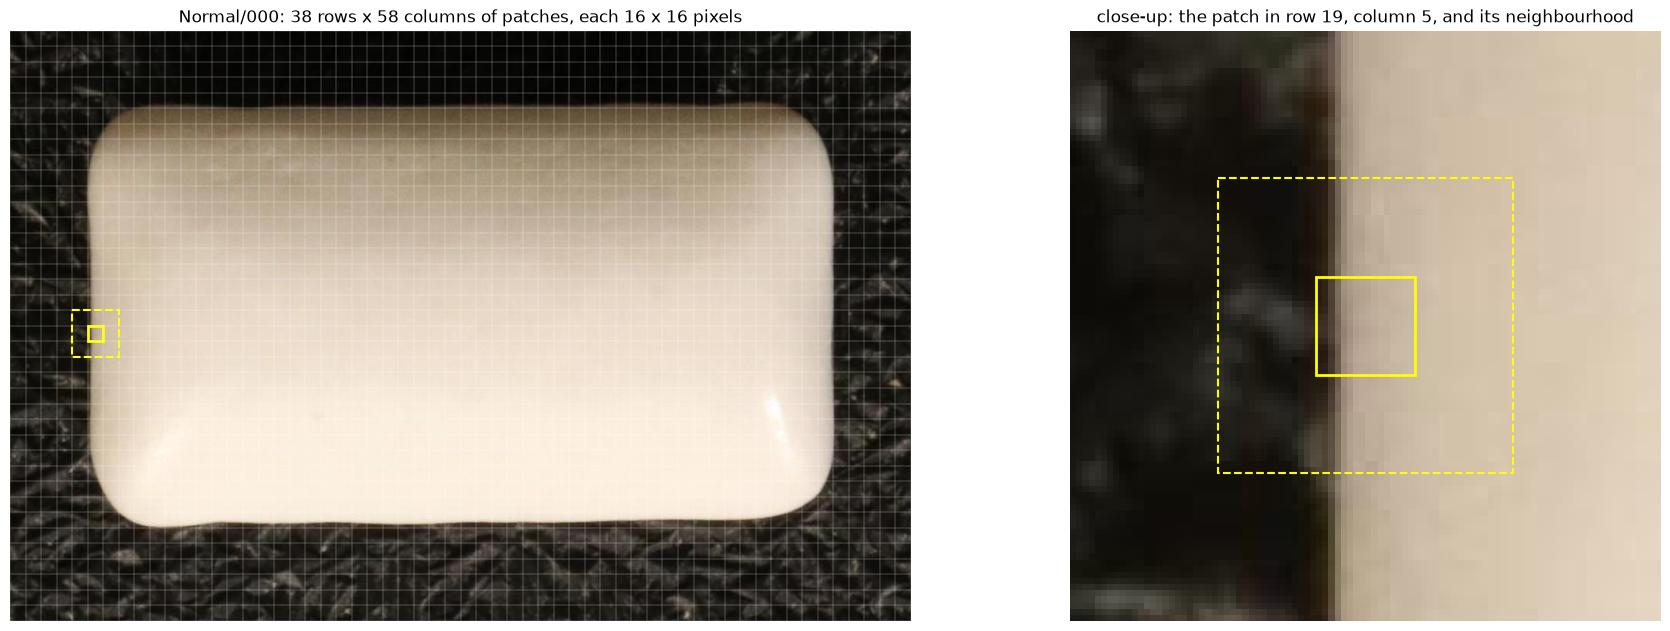

In [19]:
example_crop = Image.open(full_path(CROP_DIR, example["crop_image"])).convert("RGB")
example_box = crops.set_index("image").loc[example["image"]]
row, col = GRID[0] // 2, int(example_box["gum_left"] - example_box["crop_left"]) // PATCH_PIXELS
half = NEIGHBOURHOOD // 2
zoom = patch_square(row, col, patch_pixels=PATCH_PIXELS, size=6 * PATCH_PIXELS, crop_size=CROP_SIZE)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1.6, 1]}, layout="constrained")
axes[0].imshow(example_crop)
for x in range(0, CROP_SIZE[0] + 1, PATCH_PIXELS):
    axes[0].axvline(x - 0.5, color="white", linewidth=0.3, alpha=0.6)
for y in range(0, CROP_SIZE[1] + 1, PATCH_PIXELS):
    axes[0].axhline(y - 0.5, color="white", linewidth=0.3, alpha=0.6)
axes[1].imshow(example_crop.crop(zoom), interpolation="nearest")
for ax, (left, top) in zip(axes, [(0, 0), zoom[:2]]):
    ax.add_patch(Rectangle((col * PATCH_PIXELS - left - 0.5, row * PATCH_PIXELS - top - 0.5),
                            PATCH_PIXELS, PATCH_PIXELS, fill=False, edgecolor="yellow", linewidth=2))
    ax.add_patch(Rectangle(((col - half) * PATCH_PIXELS - left - 0.5, (row - half) * PATCH_PIXELS - top - 0.5),
                           NEIGHBOURHOOD * PATCH_PIXELS, NEIGHBOURHOOD * PATCH_PIXELS,
                            fill=False, edgecolor="yellow", linewidth=1.5, linestyle="--"))
    ax.axis("off")
axes[0].set_title(f"{short_name(example['image'])}: {GRID[0]} rows x {GRID[1]} columns of patches, "
                    f"each {PATCH_PIXELS} x {PATCH_PIXELS} pixels")
axes[1].set_title(f"close-up: the patch in row {row}, column {col}, and its neighbourhood")
plt.show()

### Why Half Size?

> The number of patches, and so the memory and the time, grows with the number of pixels. One `layer2` cell always covers the same number of picture pixels (printed above), so a bigger picture gives a bigger grid. The table shows, for the normal train photos of one split, how many patch features there would be at full, half and quarter size, and how much memory they take in half precision (2 bytes per number).

In [20]:
n_train_normal = len(splits[1][(splits[1]["split"] == "train") & ~splits[1]["is_defect"]])
cell_pixels = CROP_SIZE[0] // SHRINK // GRID[1]
size_rows = []
for shrink in [1, 2, 4]:
    grid = (CROP_SIZE[1] // shrink // cell_pixels, CROP_SIZE[0] // shrink // cell_pixels)
    n_features = n_train_normal * grid[0] * grid[1]
    size_rows.append({"size": f"1/{shrink}", "picture (width x height)": f"{CROP_SIZE[0] // shrink} x {CROP_SIZE[1] // shrink}",
                      "patch grid (rows x columns)": f"{grid[0]} x {grid[1]}", "patches per photo": grid[0] * grid[1],
                        f"patch features ({n_train_normal} photos)": n_features,
                      "memory (GB)": round(n_features * FEATURE_SIZE * 2 / 1024**3, 2)})
size_table = pd.DataFrame(size_rows).set_index("size")
size_table["compared to 1/2 size"] = size_table["patches per photo"] / PATCHES_PER_PHOTO
size_table

,picture (width x height),patch grid (rows x columns),patches per photo,patch features (347 photos),memory (GB),compared to 1/2 size
size,,,,,,
1/1,928 x 608,76 x 116,8816,3059152,8.75,4.00
1/2,464 x 304,38 x 58,2204,764788,2.19,1.00
1/4,232 x 152,19 x 29,551,191197,0.55,0.25


> **What we see:**
>
> - At half size the picture is 464 x 304 pixels. `layer2` makes a grid of 38 rows x 58 columns with 512 channels (one cell per 8 x 8 pixels of the picture), and `layer3` a grid of 19 rows x 29 columns with 1,024 channels (one cell per 16 x 16 pixels).
> - After stretching `layer3` to the `layer2` grid, every patch has 512 + 1,024 = 1,536 numbers.
> - So PatchCore sees each crop as 38 x 58 = 2,204 patches, and one patch stands for 16 x 16 pixels of the crop.
> - At full size, the 347 normal train photos would give 3,059,152 patch features (8.75 GB): 4 times as many as at half size (764,788 features, 2.19 GB). Choosing the coreset and scoring would take much longer too, because both the number of patches and the memory bank would be 4 times bigger. A quarter size would be light (0.55 GB), but notebook 3.1 showed that a typical crack is only 1 pixel thick there. Half size is the balance.

## Step 2: Learn the Normal Patches of Each Split

### Build the Memory Bank

> For each split:
>
> 1. Take its normal train photos, the only photos PatchCore learns from.
> 2. Turn them into patch features (`features_of_photos()`).
> 3. Choose the coreset (`greedy_coreset()`) and keep those rows as the memory bank, in full precision (`float32`) on the GPU.
> 4. Remember where every memory bank patch comes from (`sources`: which train photo, which grid row, which grid column), for the figures below and the demo.
>
> For split 1 we also keep `COVERAGE_SAMPLE` random normal patch features (`normal_sample`), and a random pick of as many patches as the coreset has (`random_pick`), for the comparison below. Then the big feature table is deleted (`del`) to free the memory.

In [21]:
banks, sources, train_photos, timings = {}, {}, {}, []
rng = np.random.default_rng(SEED)
for s, split in splits.items():
    train_photos[s] = split.loc[(split["split"] == "train") & ~split["is_defect"], "crop_image"].tolist()
    start_time = time.perf_counter()
    features = features_of_photos(extractor, train_photos[s], patches_per_photo=PATCHES_PER_PHOTO,
                                  feature_size=FEATURE_SIZE, desc=f"Split {s}: features of the normal train photos")
    feature_seconds = time.perf_counter() - start_time

    start_time = time.perf_counter()
    chosen = greedy_coreset(features, share=CORESET_SHARE, projection_size=PROJECTION_SIZE, seed=SEED,
                            desc=f"Split {s}: choosing the coreset")
    coreset_seconds = time.perf_counter() - start_time

    banks[s] = torch.from_numpy(features[chosen].astype(np.float32)).to(DEVICE)
    sources[s] = np.stack([chosen // PATCHES_PER_PHOTO, chosen % PATCHES_PER_PHOTO // GRID[1], chosen % GRID[1]], axis=1)
    if s == 1:
        normal_sample = features[rng.choice(len(features), size=COVERAGE_SAMPLE, replace=False)].astype(np.float32)
        random_pick = features[rng.choice(len(features), size=len(chosen), replace=False)].astype(np.float32)
    timings.append({"split": s, "normal train photos": len(train_photos[s]), "patch features": len(features),
                    "memory (GB)": round(features.nbytes / 1024**3, 2), "memory bank": len(chosen),
                    "share kept %": round(100 * len(chosen) / len(features), 2),
                    "seconds for features": round(feature_seconds, 1), "seconds for coreset": round(coreset_seconds, 1)})
    del features

pd.DataFrame(timings).set_index("split")

Split 3: choosing the coreset: 100%|██████████| 7647/7647 [00:10<00:00, 713.82it/s]


,normal train photos,patch features,memory (GB),memory bank,share kept %,seconds for features,seconds for coreset
split,,,,,,,
1,347,764788,2.19,7648,1.0,11.3,11.2
2,347,764788,2.19,7648,1.0,10.4,11.0
3,347,764788,2.19,7648,1.0,10.4,11.0


> **What we see:** every split has 347 normal train photos, so 347 x 2,204 = 764,788 patch features (2.19 GB in half precision). The coreset keeps 7,648 of them (1.0%). The two time columns show how long this computer needed for each part.

### Which Patches Did the Coreset Keep?

> The yellow squares are the kept patches of two normal train photos of split 1: the photo with the most kept patches, and a photo with the median number. On the right, for every position of the patch grid: how many kept patches come from that position, over all train photos of split 1.

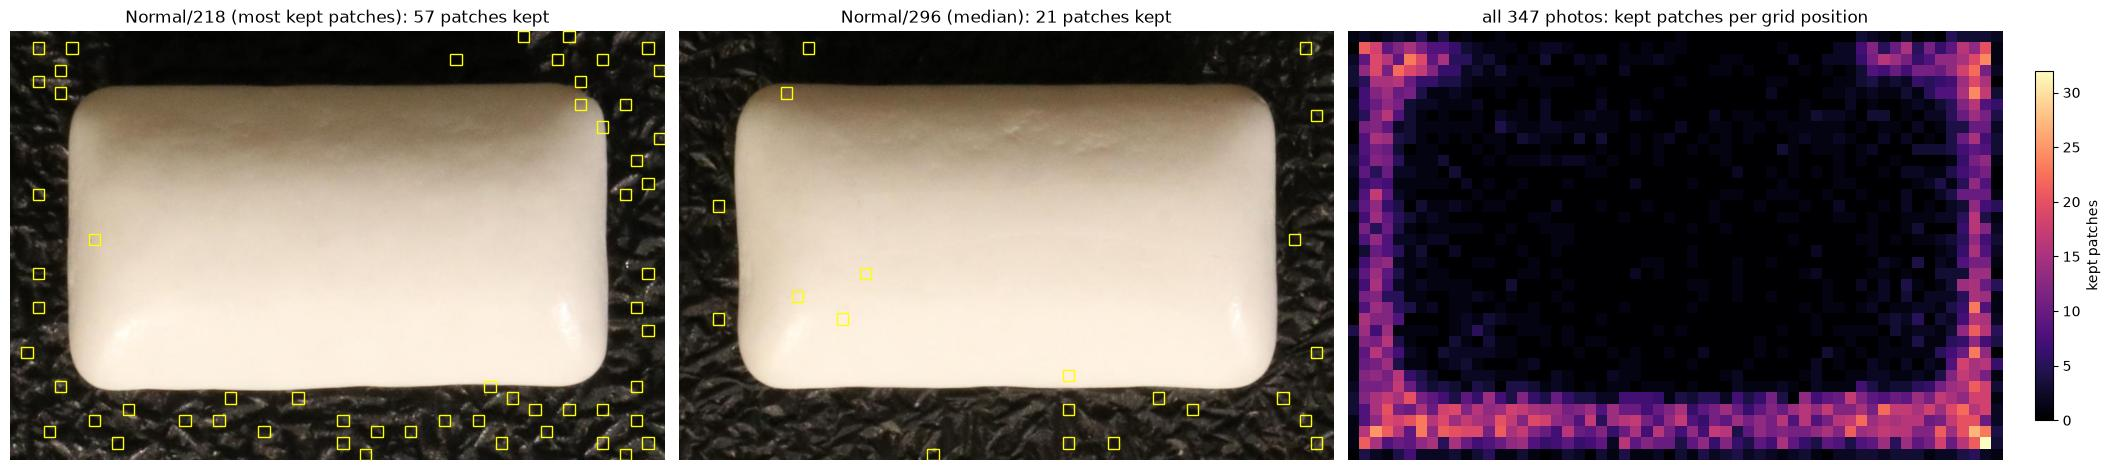

Kept patches per train photo: fewest 8, median 21, most 57 (the same number for every photo would be 22.0)
Grid positions with no kept patch at all: 889 of 2,204


In [22]:
kept_per_photo = np.bincount(sources[1][:, 0], minlength=len(train_photos[1]))
kept_map = np.zeros(GRID, dtype=int)
np.add.at(kept_map, (sources[1][:, 1], sources[1][:, 2]), 1)
by_count = np.argsort(kept_per_photo, kind="stable")
examples = {"most kept patches": by_count[-1], "median": by_count[len(by_count) // 2]}

fig, axes = plt.subplots(1, 3, figsize=(21, 4.6), layout="constrained")
for ax, (label, photo_index) in zip(axes, examples.items()):
    ax.imshow(Image.open(full_path(CROP_DIR, train_photos[1][photo_index])).convert("RGB"))
    for _, r, c in sources[1][sources[1][:, 0] == photo_index]:
        ax.add_patch(Rectangle((c * PATCH_PIXELS - 0.5, r * PATCH_PIXELS - 0.5), PATCH_PIXELS, PATCH_PIXELS,
                               fill=False, edgecolor="yellow", linewidth=1))
    ax.set_title(f"{short_name(train_photos[1][photo_index])} ({label}): {kept_per_photo[photo_index]} patches kept")
    ax.axis("off")
image = axes[2].imshow(kept_map, cmap="magma")
fig.colorbar(image, ax=axes[2], shrink=0.8, label="kept patches")
axes[2].set_title(f"all {len(train_photos[1])} photos: kept patches per grid position")
axes[2].axis("off")
plt.show()

print(f"Kept patches per train photo: fewest {kept_per_photo.min()}, median {np.median(kept_per_photo):.0f}, "
      f"most {kept_per_photo.max()} (the same number for every photo would be {len(sources[1]) / len(train_photos[1]):.1f})")
print(f"Grid positions with no kept patch at all: {(kept_map == 0).sum():,} of {PATCHES_PER_PHOTO:,}")

> **What we see:**
>
> - The kept patches are not spread evenly at all: almost all of them lie on the **mat**, and only a few on the gum. That is true for the photo with the most kept patches (`Normal/218`, 57) and for the median photo (`Normal/296`, 21).
> - The map on the right shows the same for all 347 photos: a bright frame around the picture and an almost black middle, where the gum lies. Smooth gum looks the same everywhere, and PatchCore does not care where a kept patch came from, so a few kept patches of smooth gum stand for smooth gum at every place of every photo. The wrinkled mat looks different at every place, so it needs many kept patches.
> - The frame is brightest at the corners and along the bottom edge. At the edges, the network sees the end of the picture (it adds zeros around it), which makes these patches look different from all others. The bottom is probably brighter because the light comes from below (notebook 3.1), so the wrinkles there show more detail.
> - One photo gives between 8 and 57 kept patches (median 21), and 889 of the 2,204 grid positions have no kept patch at all, mostly in the middle, where the gum lies.

### Coreset or Random Pick?

> Why not just keep a random 1%? Because a random pick takes mostly the patches that are common (for example the smooth middle of the gum), and easily misses the rare normal patches: an unusual bump, a corner of the gum, a bright spot on the mat. If the memory bank misses those, PatchCore later calls them unusual and raises a false alarm on a good gum.
>
> To check this, we measure for each of the `COVERAGE_SAMPLE` random normal patches of split 1 (`normal_sample`) the distance to its nearest patch in **the coreset**, and in **a random pick** of the same size. A good memory bank leaves no normal patch far away. The table shows the mean, the median, the distance that 99% of the patches stay below, and the largest distance (`max`), which is the normal patch that is worst covered.

In [23]:
sample_on_device = torch.from_numpy(normal_sample).to(DEVICE)
to_coreset, _ = nearest_distances(sample_on_device, banks[1], chunk_rows=CHUNK_ROWS)
to_random, _ = nearest_distances(sample_on_device, torch.from_numpy(random_pick).to(DEVICE), chunk_rows=CHUNK_ROWS)
coverage = pd.DataFrame({"coreset": to_coreset.cpu().numpy(), "random pick": to_random.cpu().numpy()})

pd.DataFrame({"mean": coverage.mean(), "median": coverage.median(),
              "99% of patches are closer than": coverage.quantile(0.99), "max": coverage.max()}).T.round(2)

,coreset,random pick
mean,1.48,1.30
median,1.52,1.26
99% of patches are closer than,1.81,1.93
max,1.94,2.18


### See the Coreset in Two Dimensions

> A feature has 1,536 numbers, so we cannot draw it directly. **PCA** (principal component analysis) finds the two directions in which the normal features differ the most, and we draw every feature at its position along those two directions. `np.linalg.svd()` finds these directions (`directions[:2]`) after the average feature (`centre`) is subtracted.
>
> Gray: the normal sample. Blue: the random pick. Red: the coreset.

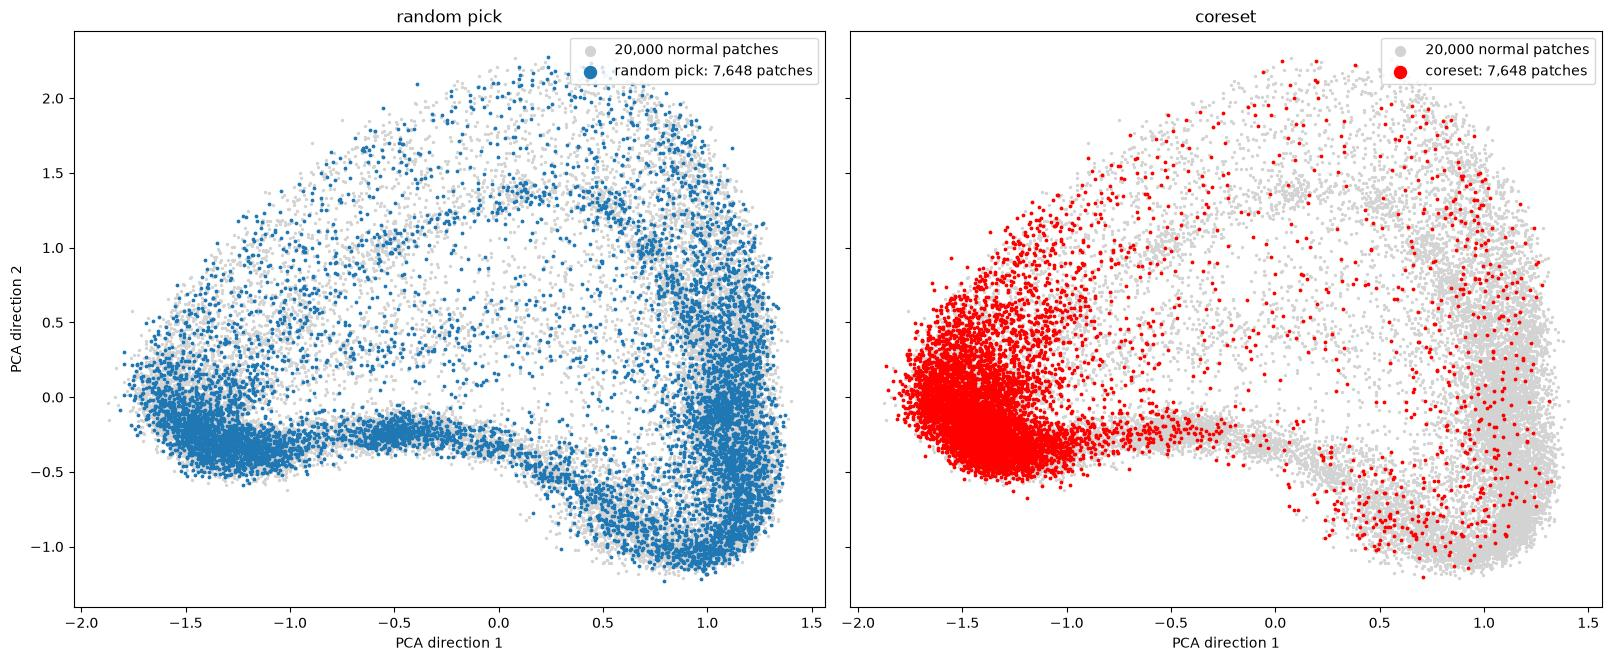

In [24]:
centre = normal_sample.mean(axis=0)
_, _, directions = np.linalg.svd(normal_sample - centre, full_matrices=False)
pca_axes = directions[:2].T
sample_2d = (normal_sample - centre) @ pca_axes

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True, layout="constrained")
for ax, (title, picked, color) in zip(axes, [("random pick", random_pick, "tab:blue"),
                                             ("coreset", banks[1].cpu().numpy(), "red")]):
    picked_2d = (picked - centre) @ pca_axes
    ax.scatter(sample_2d[:, 0], sample_2d[:, 1], s=2, color="lightgray", label=f"{COVERAGE_SAMPLE:,} normal patches")
    ax.scatter(picked_2d[:, 0], picked_2d[:, 1], s=3, color=color, label=f"{title}: {len(picked):,} patches")
    ax.set_title(title)
    ax.set_xlabel("PCA direction 1")
    ax.legend(markerscale=5, loc="upper right")
axes[0].set_ylabel("PCA direction 2")
plt.show()

> **What we see:**
>
> - **The coreset covers the worst cases better.** 99% of the normal patches are closer than 1.81 to a coreset patch, against 1.93 for the random pick. The worst-covered normal patch is 1.94 away from the coreset, against 2.18 from the random pick.
> - **The random pick is better for the common patches:** a mean of 1.30 and a median of 1.26, against 1.48 and 1.52 for the coreset. It keeps many of the common patches, so a common patch finds a very close neighbour. That matters less, because a photo's score is its *largest* patch distance: false alarms come from the badly covered patches.
> - **In the figure,** the random pick (blue) copies the gray cloud: most of its points lie where the cloud is thick, in the left part and in the band on the right. The coreset (red) puts most of its points in the left part, and only a few in the thick band on the right. Almost all kept patches lie on the mat (figure above), so the left part is most likely the mat, and the band on the right most likely the smooth gum, whose patches are all alike.
> - The figure shows only 2 of the 1,536 directions, so a part of the cloud that looks small here can be wide in the other directions. That is why the left part needs so many red points.

## Step 3: Score the Validation and Test Photos

### Score Every Photo

> For each split, every validation and test photo gets a grid of patch distances (`score_photos()`). The table `scores` gets one row per photo:
>
> - `image`, `crop_image`: the photo and its crop.
> - `part`: `val` or `test`. `is_defect`, `defect_types`: from the split file.
> - `score`: the largest patch distance, the photo's anomaly score.
> - `best_row`, `best_col`: where in the grid that most unusual patch is.
>
> The validation photos come first, then the test photos, each sorted by name.

In [25]:
scores, grids, nearest = {}, {}, {}
for s, split in splits.items():
    scored = split[split["split"].isin(["val", "test"])].sort_values(["split", "image"], ascending=[False, True])
    grids[s], nearest[s] = score_photos(extractor, banks[s], scored["crop_image"].tolist(),
                                        desc=f"Split {s}: scoring the val and test photos")
    flat_grids = grids[s].reshape(len(scored), -1)
    best = flat_grids.argmax(axis=1)
    scores[s] = pd.DataFrame({"image": scored["image"].to_numpy(), "crop_image": scored["crop_image"].to_numpy(),
                              "part": scored["split"].to_numpy(), "is_defect": scored["is_defect"].to_numpy(),
                              "defect_types": scored["defect_types"].to_numpy(), "score": flat_grids.max(axis=1),
                              "best_row": best // GRID[1], "best_col": best % GRID[1]})
    print(f"Split {s}: {(scores[s]['part'] == 'val').sum()} val and {(scores[s]['part'] == 'test').sum()} test photos scored")

Split 1: scoring the val and test photos: 100%|██████████| 27/27 [00:07<00:00,  3.47it/s]


Split 1: 60 val and 150 test photos scored


Split 2: scoring the val and test photos: 100%|██████████| 27/27 [00:07<00:00,  3.50it/s]


Split 2: 60 val and 150 test photos scored


Split 3: scoring the val and test photos: 100%|██████████| 27/27 [00:07<00:00,  3.53it/s]

Split 3: 60 val and 150 test photos scored


### Preview Before Saving

> What will be saved, one of each file per split:
>
> - `results/patchcore/split_1_scores.csv`: the table `scores`.
> - `results/patchcore/split_1_patch_scores.npz`: `images` (the photos, in the same order as the CSV), `grids` (the patch distances) and `nearest` (the nearest memory bank row of every patch).
> - `models/patchcore/split_1_memory_bank.npz`: `features` (the memory bank), `sources` (train photo number, grid row and grid column of every memory bank patch) and `train_photos` (the train crops, in the order of those numbers). The memory bank is saved in half precision, which loses nothing: its numbers came from the half-precision table.
>
> `.npz` is numpy's file format for several arrays in one file. Below are the sizes of what will be saved, and the first validation rows of split 1.

In [26]:
for s in SPLITS:
    print(f"Split {s}: scores {scores[s].shape[0]} rows x {scores[s].shape[1]} columns | grids {grids[s].shape} | "
          f"nearest {nearest[s].shape} | memory bank {tuple(banks[s].shape)} | sources {sources[s].shape}")
scores[1][scores[1]["part"] == "val"].head()

Split 1: scores 210 rows x 8 columns | grids (210, 38, 58) | nearest (210, 38, 58) | memory bank (7648, 1536) | sources (7648, 3)
Split 2: scores 210 rows x 8 columns | grids (210, 38, 58) | nearest (210, 38, 58) | memory bank (7648, 1536) | sources (7648, 3)
Split 3: scores 210 rows x 8 columns | grids (210, 38, 58) | nearest (210, 38, 58) | memory bank (7648, 1536) | sources (7648, 3)


,image,crop_image,part,is_defect,defect_types,score,best_row,best_col
0,chewinggum/Data/Images/Anomaly/005.JPG,images/Anomaly/005.png,val,True,corner missing,3.054955,10,29
1,chewinggum/Data/Images/Anomaly/015.JPG,images/Anomaly/015.png,val,True,"chunk of gum missing,small cracks",3.174173,15,21
2,chewinggum/Data/Images/Anomaly/023.JPG,images/Anomaly/023.png,val,True,chunk of gum missing,2.735073,29,27
3,chewinggum/Data/Images/Anomaly/038.JPG,images/Anomaly/038.png,val,True,"corner missing,small cracks",3.018801,28,46
4,chewinggum/Data/Images/Anomaly/043.JPG,images/Anomaly/043.png,val,True,chunk of gum missing,2.887622,15,40


### Save

> `os.makedirs(..., exist_ok=True)` makes the folders if they do not exist yet. Running this cell again replaces the files. At the end, every saved file is listed with its size.

In [27]:
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

for s in SPLITS:
    scores[s].to_csv(os.path.join(RESULTS_DIR, f"split_{s}_scores.csv"), index=False)
    np.savez_compressed(os.path.join(RESULTS_DIR, f"split_{s}_patch_scores.npz"),
                        images=scores[s]["image"].to_numpy(dtype=str), grids=grids[s].astype(np.float32),
                        nearest=nearest[s].astype(np.int32))
    np.savez(os.path.join(MODELS_DIR, f"split_{s}_memory_bank.npz"),
             features=banks[s].cpu().numpy().astype(np.float16), sources=sources[s].astype(np.int32),
             train_photos=np.array(train_photos[s], dtype=str))

for folder in [RESULTS_DIR, MODELS_DIR]:
    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        print(f"{os.path.relpath(path, ROOT_DIR)}: {os.path.getsize(path) / 1024:,.0f} KB")

results\patchcore\split_1_patch_scores.npz: 1,977 KB
results\patchcore\split_1_scores.csv: 20 KB
results\patchcore\split_2_patch_scores.npz: 1,975 KB
results\patchcore\split_2_scores.csv: 20 KB
results\patchcore\split_3_patch_scores.npz: 1,977 KB
results\patchcore\split_3_scores.csv: 20 KB
models\patchcore\split_1_memory_bank.npz: 23,063 KB
models\patchcore\split_2_memory_bank.npz: 23,063 KB
models\patchcore\split_3_memory_bank.npz: 23,063 KB


### Read the Files Back

> A quick check that the saved files hold what we meant to save: we read every file again and compare it with what is still in memory.
>
> - **same photo order:** the photos in the `.npz` file are in the same order as the rows of the CSV.
> - **scores match the grids:** the largest value of every saved grid is the saved score.
> - **memory bank exact:** the saved memory bank, turned back into full precision, is exactly the one in memory.

In [28]:
for s in SPLITS:
    saved = pd.read_csv(os.path.join(RESULTS_DIR, f"split_{s}_scores.csv"))
    with (np.load(os.path.join(RESULTS_DIR, f"split_{s}_patch_scores.npz")) as patch_file,
          np.load(os.path.join(MODELS_DIR, f"split_{s}_memory_bank.npz")) as bank_file):
        same_order = np.array_equal(patch_file["images"], saved["image"].to_numpy(dtype=str))
        scores_match = np.allclose(patch_file["grids"].reshape(len(saved), -1).max(axis=1), saved["score"])
        bank_exact = np.array_equal(bank_file["features"].astype(np.float32), banks[s].cpu().numpy())
    print(f"Split {s}: same photo order {same_order}, scores match the grids {scores_match}, memory bank exact {bank_exact}")

Split 1: same photo order True, scores match the grids True, memory bank exact True
Split 2: same photo order True, scores match the grids True, memory bank exact True
Split 3: same photo order True, scores match the grids True, memory bank exact True


## Step 4: First Look at the Validation Photos

### Scores of Normal and Defect Validation Photos

> For each split, the validation photos: the AUROC, and a histogram of their scores. A good PatchCore gives the defect photos (red) higher scores than the normal photos (green), with little overlap. Under the figure, the score ranges, and how many defect photos score higher than every normal photo.
>
> This is only a first look, with 10 defect photos per split. The real comparison with YOLO, with the PASS/REJECT limit and the 150 test photos, comes in step 5.

Split 1: AUROC 1.000 | normal scores 1.88 to 2.32 | defect scores 2.56 to 3.17 | defect photos above every normal photo: 10 of 10
Split 2: AUROC 1.000 | normal scores 1.88 to 2.28 | defect scores 2.71 to 3.07 | defect photos above every normal photo: 10 of 10
Split 3: AUROC 0.992 | normal scores 1.90 to 2.21 | defect scores 2.14 to 3.61 | defect photos above every normal photo: 9 of 10


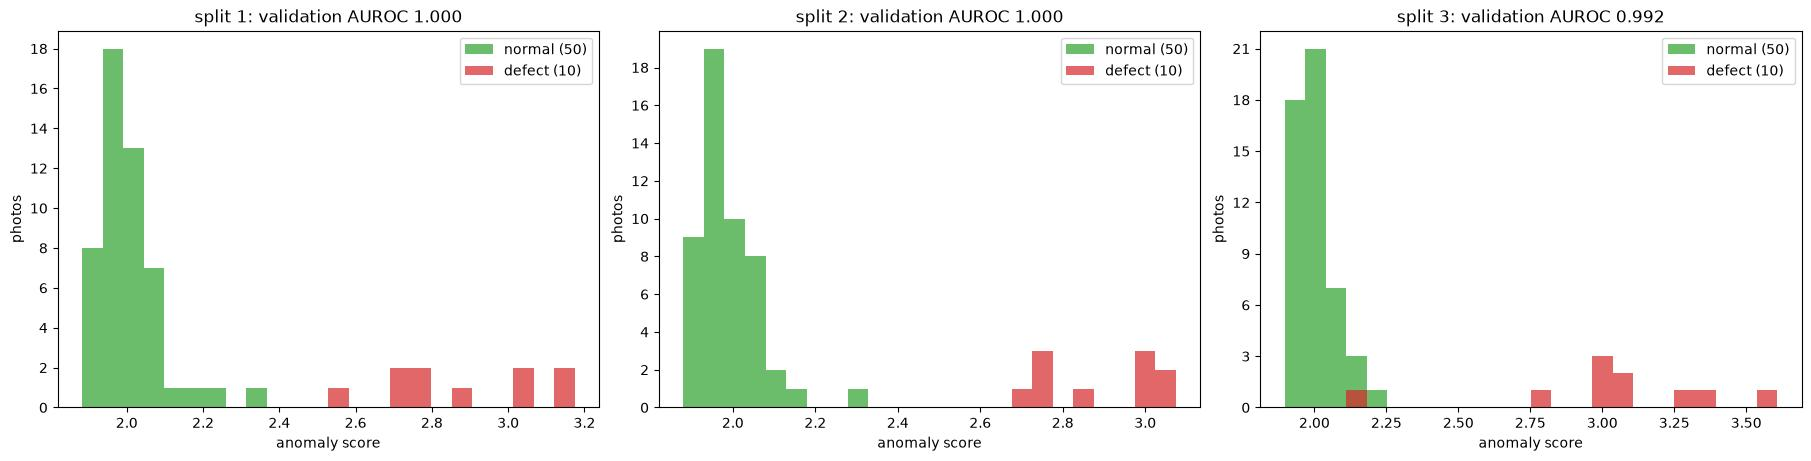

In [29]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(18, 4.5), layout="constrained")
for ax, s in zip(axes, SPLITS):
    val = scores[s][scores[s]["part"] == "val"]
    normal, defect = val.loc[~val["is_defect"], "score"], val.loc[val["is_defect"], "score"]
    auroc = roc_auc_score(val["is_defect"], val["score"])
    bins = np.linspace(val["score"].min(), val["score"].max(), 25)
    ax.hist(normal, bins=bins, color="tab:green", alpha=0.7, label=f"normal ({len(normal)})")
    ax.hist(defect, bins=bins, color="tab:red", alpha=0.7, label=f"defect ({len(defect)})")
    ax.set_title(f"split {s}: validation AUROC {auroc:.3f}")
    ax.set_xlabel("anomaly score")
    ax.set_ylabel("photos")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
    print(f"Split {s}: AUROC {auroc:.3f} | normal scores {normal.min():.2f} to {normal.max():.2f} | "
          f"defect scores {defect.min():.2f} to {defect.max():.2f} | "
          f"defect photos above every normal photo: {(defect > normal.max()).sum()} of {len(defect)}")
plt.show()

> **What we see:**
>
> - **Splits 1 and 2: AUROC 1.000.** All 10 defect photos score higher than every normal photo, with an empty gap between them. In split 1, the normal photos score 1.88 to 2.32 and the defect photos 2.56 to 3.17.
> - **Split 3: AUROC 0.992.** One defect photo scores only 2.14, below the highest normal photo (2.21), so 9 of 10 defect photos are above every normal photo. In the histogram it is the small red bar inside the green bars.
> - The normal photos score almost the same in all three splits (from 1.88 to at most 2.32), so the three memory banks learned about the same idea of normal gum.
> - So on the validation photos, PatchCore already separates good and bad gum very well, without having seen a single defect. Whether this holds on the 150 test photos is checked in step 5.

### Heatmaps of the Defect Validation Photos

> The defect validation photos of split 1, highest score first, with their heatmaps. The white line is the edge of the real defect from the mask. PatchCore never saw these masks: if the red area lies on the white line, PatchCore found the defect by itself.
>
> All heatmaps use the same colours: dark blue at the typical distance of a normal patch (the median of all patch distances of the normal validation photos), red at the highest validation score of split 1. Under the figure, both values.

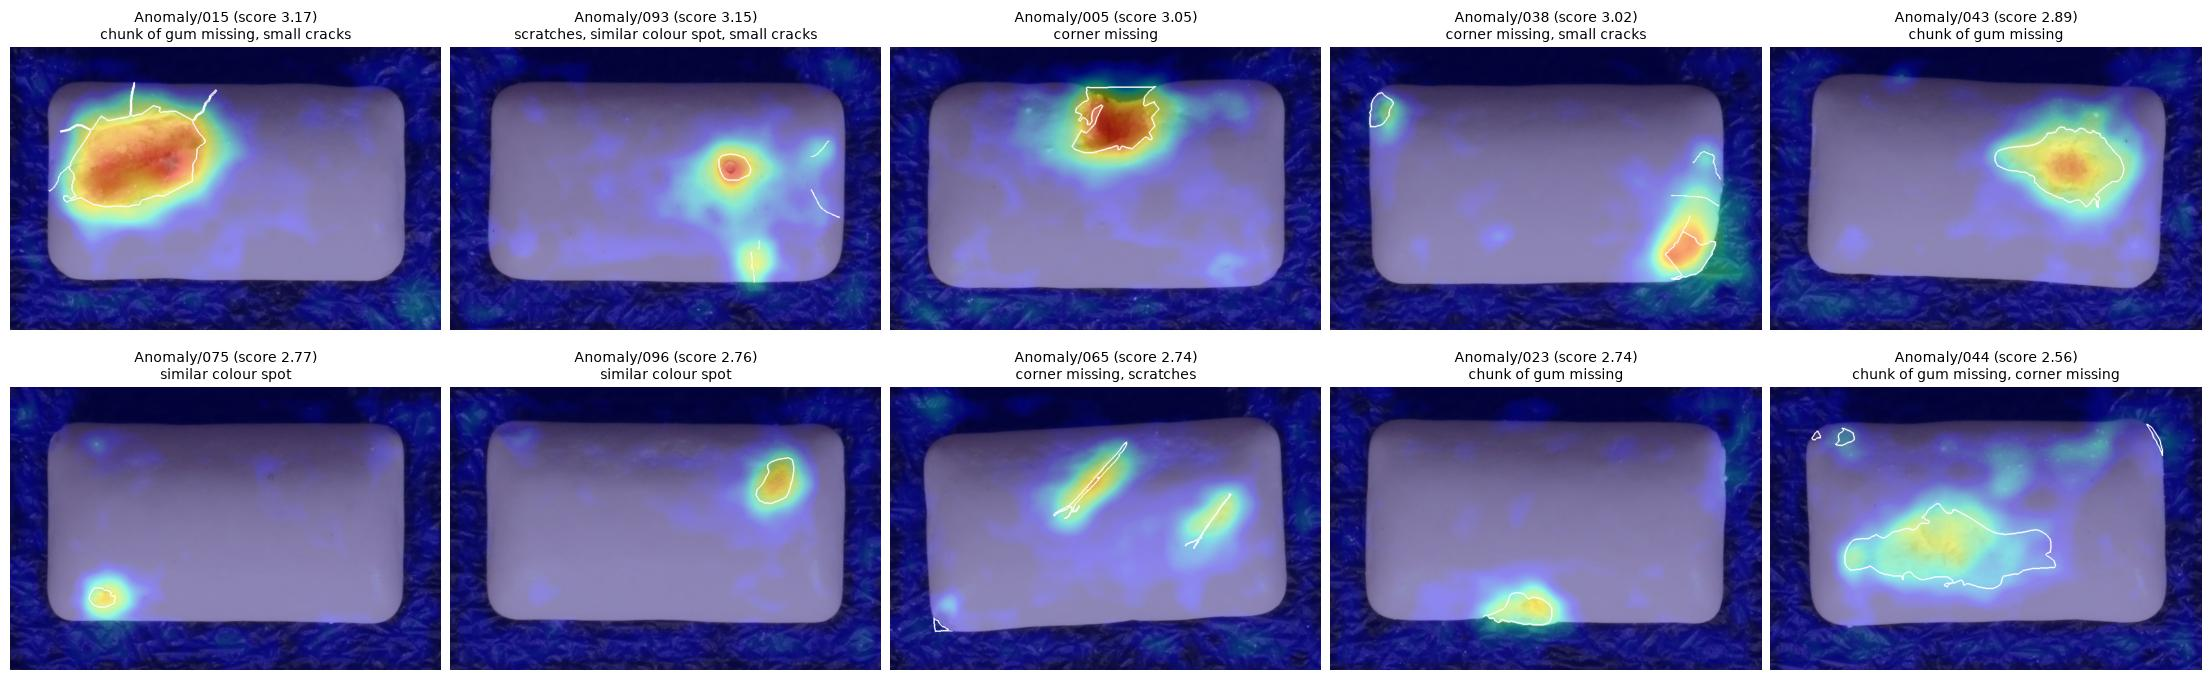

Colours: dark blue at 1.55 (median patch distance of the normal validation photos), red at 3.17 (highest validation score)


In [30]:
val_scores = scores[1][scores[1]["part"] == "val"]
row_of = {image: i for i, image in enumerate(scores[1]["image"])}
crop_mask_of = dict(zip(crops["image"], crops["crop_mask"]))
normal_val_rows = [row_of[image] for image in val_scores.loc[~val_scores["is_defect"], "image"]]
heat_low = float(np.median(grids[1][normal_val_rows]))
heat_high = float(val_scores["score"].max())
defect_val = val_scores[val_scores["is_defect"]].sort_values("score", ascending=False)

fig, axes = plt.subplots(2, 5, figsize=(22, 6.8), layout="constrained")
for ax, (_, photo) in zip(axes.ravel(), defect_val.iterrows()):
    crop = np.asarray(Image.open(full_path(CROP_DIR, photo["crop_image"])).convert("RGB"))
    mask = np.asarray(Image.open(full_path(CROP_DIR, crop_mask_of[photo["image"]])))
    heatmap = grid_to_heatmap(grids[1][row_of[photo["image"]]], crop_size=CROP_SIZE, sigma=BLUR_SIGMA * SHRINK)
    show_heatmap(ax, crop, heatmap, mask, vmin=heat_low, vmax=heat_high)
    ax.set_title(f"{short_name(photo['image'])} (score {photo['score']:.2f})\n"
                 f"{photo['defect_types'].replace(',', ', ')}", fontsize=10)
plt.show()
print(f"Colours: dark blue at {heat_low:.2f} (median patch distance of the normal validation photos), "
      f"red at {heat_high:.2f} (highest validation score)")

> **What we see:**
>
> - In every photo, the reddest area lies on a real defect: the missing chunks (`Anomaly/015`, `043`, `023`), the missing corner pieces (`005`, `038`), the colour spots (`093`, `075`, `096`) and the scratches (`065`). PatchCore found them without ever seeing a mask or a defect.
> - Some parts of the defects get little or no colour: the thin cracks next to the chunk of `Anomaly/015` and on the right of `Anomaly/093`, and the tiny marked areas in the corners of `Anomaly/038`, `065` and `044`. Thin and very small defects are the hardest for PatchCore.
> - `Anomaly/044` has the lowest score (2.56). Its missing chunk is wide but shallow, and looks only a little different from normal gum, so its heatmap is only green and yellow.

### The Most Unusual Normal Validation Photos

> The 3 normal validation photos of split 1 with the highest scores, with the same colours as above. These are the good gums PatchCore finds most unusual: if good gums get rejected later, they will look like these.

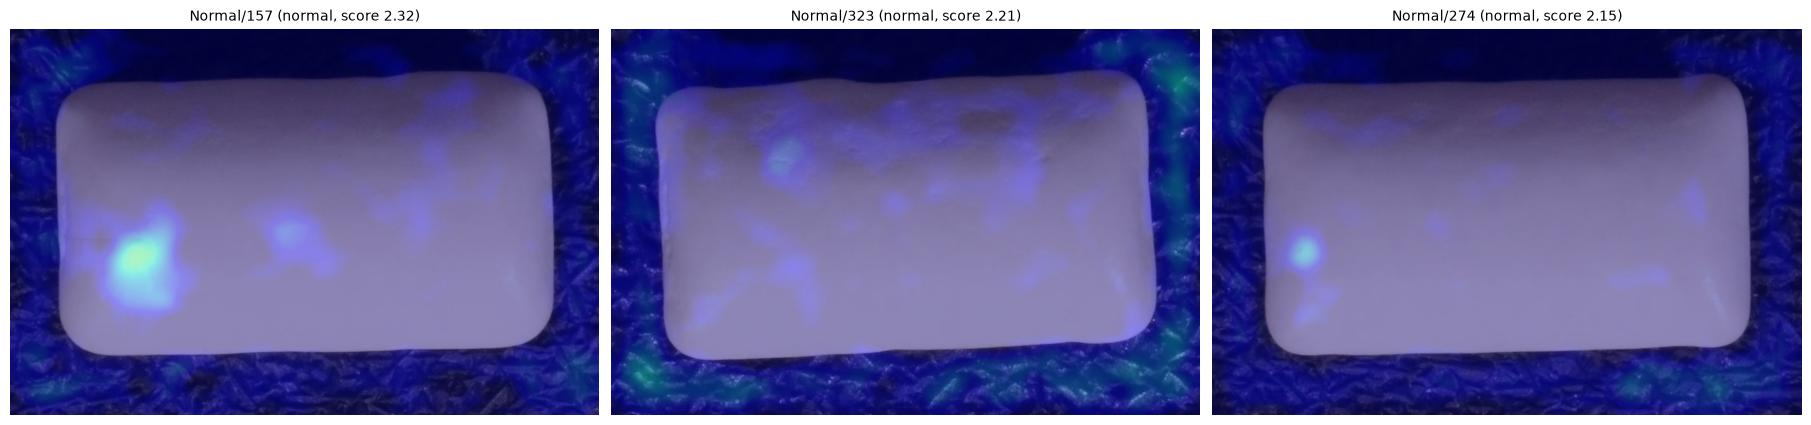

In [31]:
top_normal = val_scores[~val_scores["is_defect"]].sort_values("score", ascending=False).head(3)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), layout="constrained")
for ax, (_, photo) in zip(axes, top_normal.iterrows()):
    crop = np.asarray(Image.open(full_path(CROP_DIR, photo["crop_image"])).convert("RGB"))
    heatmap = grid_to_heatmap(grids[1][row_of[photo["image"]]], crop_size=CROP_SIZE, sigma=BLUR_SIGMA * SHRINK)
    show_heatmap(ax, crop, heatmap, None, vmin=heat_low, vmax=heat_high)
    ax.set_title(f"{short_name(photo['image'])} (normal, score {photo['score']:.2f})", fontsize=10)
plt.show()

> **What we see:**
>
> - The three most unusual good gums score 2.32, 2.21 and 2.15, all below the lowest defect photo of split 1 (2.56).
> - Their heatmaps are mostly blue, with only small green spots: a spot on the left side of the gum in `Normal/157` and `Normal/274`, and the uneven gum surface and the mat near the edges of the picture in `Normal/323`. Places like these could cause a false alarm later.

### Why Is a Patch Unusual?

> For 3 defect validation photos of split 1 (the highest, a middle and the lowest score), we show close-ups of `CLOSE_UP` x `CLOSE_UP` crop pixels. The yellow square is the patch itself:
>
> - **top row:** the most unusual patch of the photo (the one that gives its score), and next to it its nearest patch in the memory bank,
> - **bottom row:** a typical patch of the same photo (the one with the median distance), and next to it its nearest patch in the memory bank.
>
> The distance is written above each pair. A typical patch has a very similar normal patch in the memory bank, so its distance is small. A defect patch has none: even its nearest normal patch is different, so the distance is large. That is the whole idea of PatchCore.
>
> The close-ups are much bigger than one patch, because a patch feature describes more than its own 16 x 16 pixels: its 3 x 3 neighbourhood, and `layer3` even sees a larger area of the picture. So the difference can also lie just outside the yellow square.

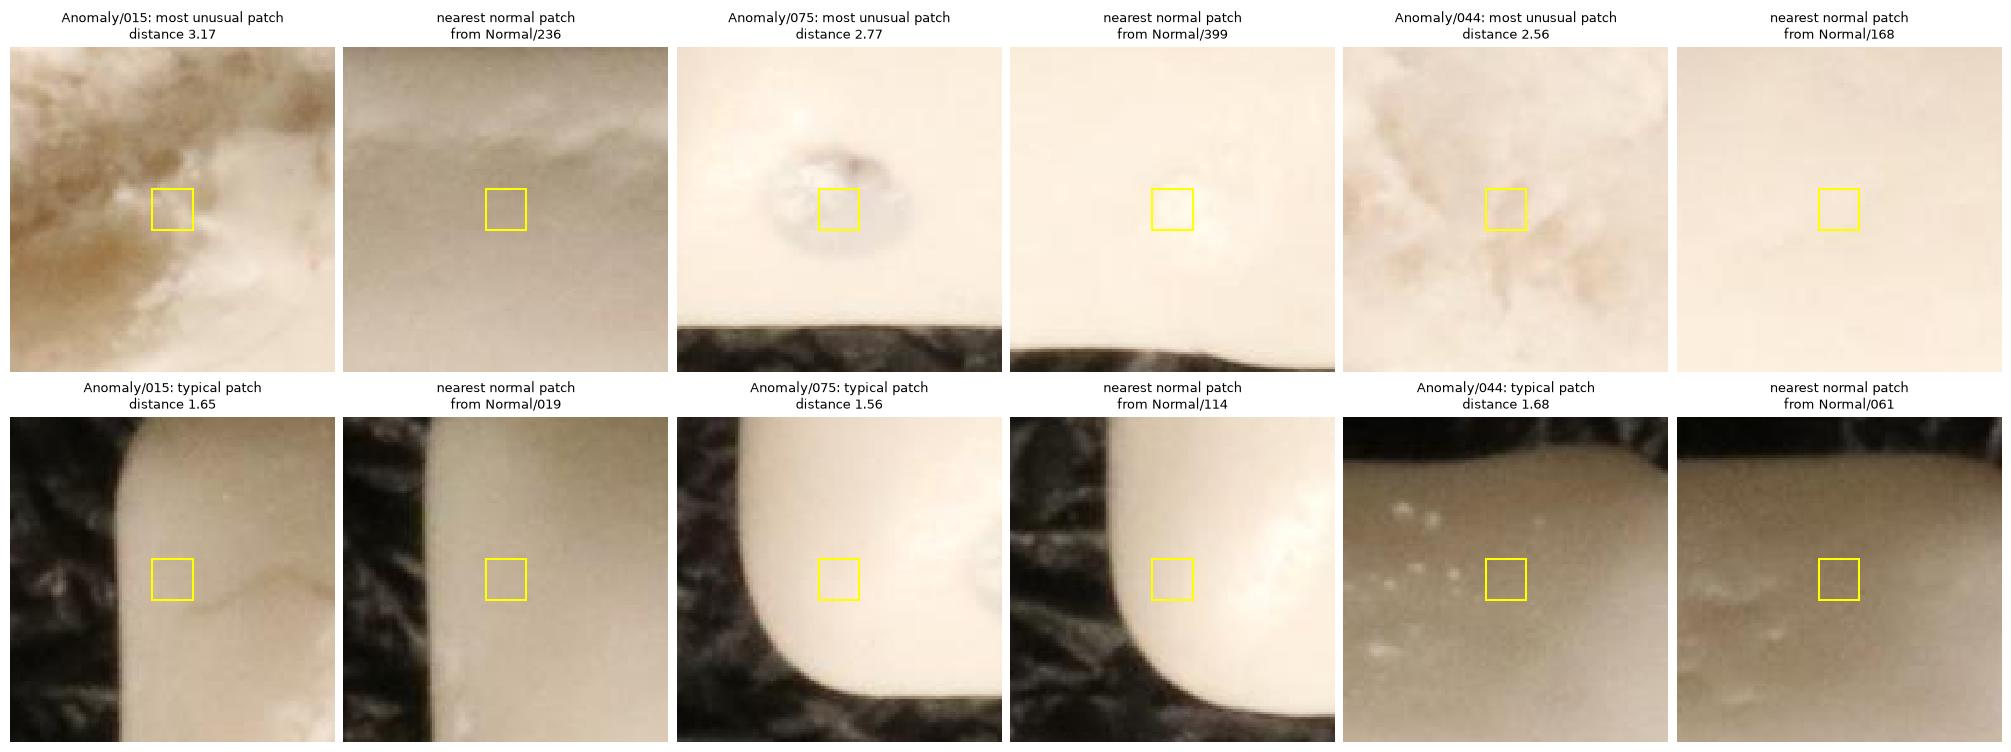

In [32]:
picked = defect_val.iloc[[0, len(defect_val) // 2, len(defect_val) - 1]]

fig, axes = plt.subplots(2, 6, figsize=(20, 7.4), layout="constrained")
for k, (_, photo) in enumerate(picked.iterrows()):
    grid, near = grids[1][row_of[photo["image"]]], nearest[1][row_of[photo["image"]]]
    crop = Image.open(full_path(CROP_DIR, photo["crop_image"])).convert("RGB")
    median_patch = np.argsort(grid.ravel(), kind="stable")[grid.size // 2]
    for line, (r, c) in enumerate([(photo["best_row"], photo["best_col"]), divmod(median_patch, GRID[1])]):
        source_photo, source_row, source_col = sources[1][near[r, c]]
        source_crop = Image.open(full_path(CROP_DIR, train_photos[1][source_photo])).convert("RGB")
        for j, (picture, rr, cc) in enumerate([(crop, r, c), (source_crop, source_row, source_col)]):
            ax = axes[line, 2 * k + j]
            square = patch_square(rr, cc, patch_pixels=PATCH_PIXELS, size=CLOSE_UP, crop_size=CROP_SIZE)
            ax.imshow(picture.crop(square), interpolation="nearest")
            ax.add_patch(Rectangle((cc * PATCH_PIXELS - square[0] - 0.5, rr * PATCH_PIXELS - square[1] - 0.5),
                                   PATCH_PIXELS, PATCH_PIXELS, fill=False, edgecolor="yellow", linewidth=1.5))
            ax.axis("off")
        kind = "most unusual patch" if line == 0 else "typical patch"
        axes[line, 2 * k].set_title(f"{short_name(photo['image'])}: {kind}\ndistance {grid[r, c]:.2f}", fontsize=9)
        axes[line, 2 * k + 1].set_title(f"nearest normal patch\nfrom {short_name(train_photos[1][source_photo])}", fontsize=9)
plt.show()

> **What we see:**
>
> - `Anomaly/015` (highest score): the most unusual patch lies in the torn, brown chunk. Its nearest normal patch (from `Normal/236`) is smooth gum in shadow. Distance 3.17.
> - `Anomaly/075` (middle): the patch lies on the round colour spot. Its nearest normal patch (from `Normal/399`) is plain gum without any spot: the memory bank has no patch with a spot like this. Distance 2.77.
> - `Anomaly/044` (lowest): the patch lies in the blotchy area of the missing chunk. Its nearest normal patch (from `Normal/168`) is plain gum. The difference is easy to miss for the eye, and the distance is the smallest of the three: 2.56.
> - On the bottom row, the typical patches look almost the same as their nearest normal patches (a gum edge next to a gum edge, a gum corner next to a gum corner), with distances of only 1.56 to 1.68.
> - The three top distances, 3.17, 2.77 and 2.56, are exactly the scores of these photos in the heatmap titles: a photo's score is the distance of its most unusual patch.

## Summary

> **What this notebook did**
>
> - Built PatchCore with PyTorch: a WideResNet-50-2 pretrained on ImageNet turns every crop (at half size) into 2,204 patch features of 1,536 numbers each.
> - For each split, learned from the 347 normal train photos only: 764,788 normal patch features, of which a greedy coreset keeps 7,648 (1%) as the memory bank. Almost all kept patches lie on the wrinkled mat, very few on the smooth gum, and the coreset covers the rare normal patches better than a random pick.
> - Scored every validation and test photo: the distance of every patch to its nearest normal patch (the heatmap), and the largest distance as the photo's score.
> - Saved the scores (`results/patchcore/`) and the memory banks (`models/patchcore/`), and read them back to check them.
> - Looked only at the validation photos: AUROC 1.000, 1.000 and 0.992 for splits 1, 2 and 3. Only one defect photo (split 3) scores below a normal photo. The heatmaps point at the real defects; thin cracks and tiny corner pieces are the hardest.
>
> **Data leakage:** PatchCore learned from normal train photos only, every setting comes from the paper or from earlier notebooks, and the test scores were saved without being looked at.
>
> **Next:** `notebooks/4_modeling/4.2_train_yolo.ipynb`